In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt
import numpy as np

In [60]:
import os
os.chdir(os.path.expanduser('~/Desktop'))

import pandas as pd
df_train = pd.read_parquet('P03_train.pq')
df_test = pd.read_parquet('P03_test.pq')

In [3]:
df_train.head()

,id,flag,pre_since_opened,pre_since_confirmed,pre_pterm,pre_fterm,pre_till_pclose,pre_till_fclose,pre_loans_credit_limit,pre_loans_next_pay_summ,...,enc_paym_21,enc_paym_22,enc_paym_23,enc_paym_24,enc_loans_account_holder_type,enc_loans_credit_status,enc_loans_credit_type,enc_loans_account_cur,pclose_flag,fclose_flag
0,41794,0,3,9,16,9,15,14,16,3,...,3,3,3,4,1,3,4,1,0,0
1,160704,0,9,6,0,1,0,4,1,3,...,3,3,3,4,1,2,3,1,0,0
2,41771,0,12,16,14,8,10,11,10,2,...,3,3,3,4,1,2,3,1,0,1
3,160727,0,7,9,17,16,14,8,14,3,...,3,3,3,4,1,2,4,1,0,0
4,160729,0,9,9,4,8,1,11,10,3,...,3,3,3,4,1,2,3,1,1,1


In [8]:
df_train['flag'].value_counts()

flag
0    169574
1      5426
Name: count, dtype: int64

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

df = df_train.drop(columns = "id")

for col in df.columns:
    plt.figure(figsize=(6,4))
    sns.kdeplot(data=df, x=col, hue='flag', common_norm=False)
    plt.title(col)
    plt.show()

In [ ]:
missing_by_class = df.groupby('flag').apply(lambda x: x.isnull().mean()).T
missing_by_class['diff'] = missing_by_class[1] - missing_by_class[0]
missing_by_class.sort_values('diff', key=abs, ascending=False)

In [16]:
# Look for suspicious placeholder values
for col in df.columns:
    print(col, df[col].unique()[:10])  # eyeball a sample of unique values

flag [0 1]
pre_since_opened [ 3  9 12  7  5 19  1 17  4 13]
pre_since_confirmed [ 9  6 16  2  0 10 13  5  1 14]
pre_pterm [16  0 14 17  4 11  7  1 15  2]
pre_fterm [ 9  1  8 16  5 15 14 10  7 13]
pre_till_pclose [15  0 10 14  1 12  8 16  7  2]
pre_till_fclose [14  4 11  8  2  0  5 10 15  6]
pre_loans_credit_limit [16  1 10 14  8 17  9 12  3 13]
pre_loans_next_pay_summ [3 2 6 4 1 0 5]
pre_loans_outstanding [3 4 5 2 1]
pre_loans_total_overdue [0]
pre_loans_max_overdue_sum [1 2 3]
pre_loans_credit_cost_rate [ 0  2  7 11  5  1  4  8  9 13]
pre_loans5 [ 6  0  3  5  2 16]
pre_loans530 [16 13  6 18  0  3  2 15 12]
pre_loans3060 [5 8 7 2]
pre_loans6090 [4 1]
pre_loans90 [ 8 14 19 13]
is_zero_loans5 [1 0]
is_zero_loans530 [0 1]
is_zero_loans3060 [1 0]
is_zero_loans6090 [1 0]
is_zero_loans90 [1 0]
pre_util [16  0  5 18  1  4 19  7  9 11]
pre_over2limit [ 2  5 13 17 14 15  8  1  3  4]
pre_maxover2limit [ 3 17  4 11  0 10 15  5 16 13]
is_zero_util [1 0]
is_zero_over2limit [1 0]
is_zero_maxover2lim

In [61]:
cols_to_drop = ["id", "pre_loans_total_overdue", "pre_loans6090", 
                'pre_loans5', 'pre_loans530', 'pre_loans3060', 'pre_loans90', "enc_loans_account_cur", "enc_loans_account_holder_type" ]


df_train = df_train.drop(columns=cols_to_drop)
df_test = df_test.drop(columns=cols_to_drop)

In [62]:
target = "flag"
X = df_train.drop(columns=[target])
y = df_train[target]


print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (175000, 51)
y shape: (175000,)


In [63]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (140000, 51)
y_train shape: (140000,)
X_test shape: (35000, 51)
y_test shape: (35000,)


In [64]:
import optuna
import lightgbm as lgb
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from imblearn.over_sampling import SMOTE  # or RandomOverSampler
import numpy as np


def objective(trial):
    params = {
        'num_leaves': trial.suggest_int('num_leaves', 15, 127),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'verbosity': -1,
    }

    # Use the ORIGINAL, unbalanced training data here — not X_train_over
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = []

    for train_idx, val_idx in skf.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        # Oversample ONLY the training fold — validation fold stays untouched/real
        os = RandomOverSampler(random_state=42)
        X_tr_res, y_tr_res = os.fit_resample(X_tr, y_tr)

        model = LGBMClassifier(**params)
        model.fit(
            X_tr_res, y_tr_res,
            eval_set=[(X_val, y_val)],  # validation stays real, imbalanced, untouched
            eval_metric='average_precision',
            callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)]
        )

        preds = model.predict_proba(X_val)[:, 1]
        score = roc_auc_score(y_val, preds)
        scores.append(score)

    return np.mean(scores)


study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=12, show_progress_bar=True)

[I 2026-08-31 11:07:54,012] A new study created in memory with name: no-name-10b3be6c-0707-45dd-ab04-cb2e3adbe65a


  0%|          | 0/12 [00:00<?, ?it/s]

[I 2026-08-31 11:07:59,187] Trial 0 finished with value: 0.7028559514909629 and parameters: {'num_leaves': 66, 'max_depth': 3, 'learning_rate': 0.2153842066026986, 'n_estimators': 636, 'min_child_samples': 28, 'subsample': 0.7257038343841472, 'colsample_bytree': 0.6602420635434287, 'reg_alpha': 9.516093502262665e-08, 'reg_lambda': 0.11621631079441945}. Best is trial 0 with value: 0.7028559514909629.
[I 2026-08-31 11:08:04,703] Trial 1 finished with value: 0.6971387301189929 and parameters: {'num_leaves': 84, 'max_depth': 9, 'learning_rate': 0.1135403267253819, 'n_estimators': 162, 'min_child_samples': 49, 'subsample': 0.7738254602807437, 'colsample_bytree': 0.7314815119177597, 'reg_alpha': 5.738293127980098e-05, 'reg_lambda': 0.21777295910836378}. Best is trial 0 with value: 0.7028559514909629.
[I 2026-08-31 11:08:26,685] Trial 2 finished with value: 0.7035769812299316 and parameters: {'num_leaves': 25, 'max_depth': 4, 'learning_rate': 0.011057319641808169, 'n_estimators': 904, 'min_ch

In [65]:
ros_final = RandomOverSampler(random_state=42)
X_train_over, y_train_over = ros_final.fit_resample(X_train, y_train)

best_clf_lgb = LGBMClassifier(**study.best_params, random_state=42, verbose=-1)
best_clf_lgb.fit(X_train_over, y_train_over)

print("=== Train (oversampled) ===")
print(classification_report(y_train_over, best_clf_lgb.predict(X_train_over)))
print("ROC-AUC (train, oversampled):", roc_auc_score(y_train_over, best_clf_lgb.predict_proba(X_train_over)[:, 1]))

print("\n=== Test (original, untouched) ===")
print(classification_report(y_test, best_clf_lgb.predict(X_test)))
print("ROC-AUC (test):", roc_auc_score(y_test, best_clf_lgb.predict_proba(X_test)[:, 1]))

=== Train (oversampled) ===
              precision    recall  f1-score   support

           0       0.75      0.72      0.73    135659
           1       0.73      0.75      0.74    135659

    accuracy                           0.74    271318
   macro avg       0.74      0.74      0.74    271318
weighted avg       0.74      0.74      0.74    271318

ROC-AUC (train, oversampled): 0.8237063896599831

=== Test (original, untouched) ===
              precision    recall  f1-score   support

           0       0.98      0.72      0.83     33915
           1       0.06      0.56      0.11      1085

    accuracy                           0.71     35000
   macro avg       0.52      0.64      0.47     35000
weighted avg       0.95      0.71      0.81     35000

ROC-AUC (test): 0.6876557753831584


In [45]:
import optuna
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score
import numpy as np
from sklearn.metrics import roc_auc_score


def objective(trial):
    params = {
        'num_leaves': trial.suggest_int('num_leaves', 15, 127),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'class_weight': 'balanced',
        'verbosity': -1,
    }

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = []

    for train_idx, val_idx in skf.split(X_train_over, y_train_over):
        X_tr, X_val = X_train_over.iloc[train_idx], X_train_over.iloc[val_idx]
        y_tr, y_val = y_train_over.iloc[train_idx], y_train_over.iloc[val_idx]

        model = LGBMClassifier(**params)
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_val, y_val)],
            eval_metric='average_precision',
            callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)]
        )

        preds = model.predict_proba(X_val)[:, 1]
        score = roc_auc_score(y_val, preds)
        scores.append(score)

    return np.mean(scores)

# Now define and run the study AFTER objective exists
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=12, show_progress_bar=True)

[I 2026-08-30 21:14:08,737] A new study created in memory with name: no-name-81b0b6bf-3732-4bb0-a32a-d3e0eccddebc


  0%|          | 0/12 [00:00<?, ?it/s]

[I 2026-08-30 21:14:56,187] Trial 0 finished with value: 0.7486722819668554 and parameters: {'num_leaves': 52, 'max_depth': 4, 'learning_rate': 0.013392618506990549, 'n_estimators': 869, 'min_child_samples': 97, 'subsample': 0.8654859230482712, 'colsample_bytree': 0.5229974934537425, 'reg_alpha': 1.2572198690477961e-05, 'reg_lambda': 1.599043554615092e-07}. Best is trial 0 with value: 0.7486722819668554.
[I 2026-08-30 21:15:25,661] Trial 1 finished with value: 0.7473831447798244 and parameters: {'num_leaves': 120, 'max_depth': 3, 'learning_rate': 0.04574057172352454, 'n_estimators': 601, 'min_child_samples': 75, 'subsample': 0.6167264524007333, 'colsample_bytree': 0.5504193375445521, 'reg_alpha': 1.3896123736836548, 'reg_lambda': 0.05573796074604599}. Best is trial 0 with value: 0.7486722819668554.
[I 2026-08-30 21:15:52,302] Trial 2 finished with value: 0.9532326037195403 and parameters: {'num_leaves': 37, 'max_depth': 8, 'learning_rate': 0.20154504043897603, 'n_estimators': 476, 'min

In [55]:
best_params = study.best_params
best_params['class_weight'] = 'balanced'
best_params['verbosity'] = -1

final_model = LGBMClassifier(**best_params)
final_model.fit(X_train, y_train)

# ---- Feature importance ----
importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': final_model.feature_importances_
}).sort_values('importance', ascending=False)

print(importance_df)

                          feature  importance
6          pre_loans_credit_limit        3415
10     pre_loans_credit_cost_rate        2823
1             pre_since_confirmed        2786
18                       pre_util        2498
2                       pre_pterm        2461
0                pre_since_opened        2136
3                       pre_fterm        2076
7         pre_loans_next_pay_summ        1863
4                 pre_till_pclose        1733
5                 pre_till_fclose        1358
51          enc_loans_credit_type        1096
8           pre_loans_outstanding        1023
25                     enc_paym_1         557
24                     enc_paym_0         450
27                     enc_paym_3         431
9       pre_loans_max_overdue_sum         421
26                     enc_paym_2         412
29                     enc_paym_5         385
28                     enc_paym_4         339
20              pre_maxover2limit         333
31                     enc_paym_7 

In [56]:
from sklearn.metrics import classification_report, roc_auc_score

best_clf_lgb = lgb.LGBMClassifier(**study.best_params, random_state=42, verbose=-1)
best_clf_lgb.fit(X_train, y_train)

print("=== Train (oversampled) ===")
print(classification_report(y_train, best_clf_lgb.predict(X_train)))
print("ROC-AUC (train):", roc_auc_score(y_train, best_clf_lgb.predict_proba(X_train)[:, 1]))

print("\n=== Test (original) ===")
print(classification_report(y_test, best_clf_lgb.predict(X_test)))
print("ROC-AUC (test):", roc_auc_score(y_test, best_clf_lgb.predict_proba(X_test)[:, 1]))

=== Train (oversampled) ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98    135659
           1       1.00      0.03      0.06      4341

    accuracy                           0.97    140000
   macro avg       0.98      0.51      0.52    140000
weighted avg       0.97      0.97      0.96    140000

ROC-AUC (train): 0.9030650272056061

=== Test (original) ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     33915
           1       0.00      0.00      0.00      1085

    accuracy                           0.97     35000
   macro avg       0.48      0.50      0.49     35000
weighted avg       0.94      0.97      0.95     35000

ROC-AUC (test): 0.688730487101462


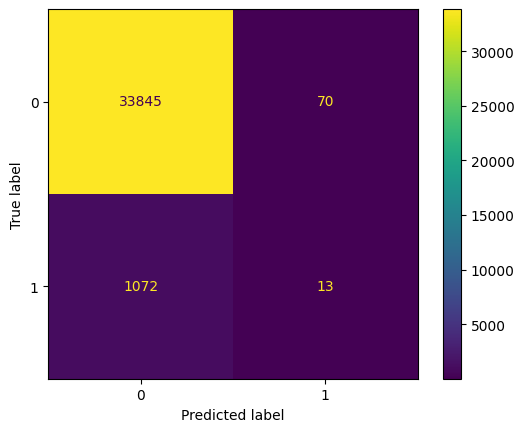

In [48]:
ConfusionMatrixDisplay.from_estimator(best_clf_lgb, X_test, y_test)

In [21]:
import optuna
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 6),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'num_leaves': trial.suggest_int('num_leaves', 15, 63),
        'random_state': 42
    }
    
    clf = lgb.LGBMClassifier(**params, verbose=-1)
    clf.fit(X_train, y_train)
    
    proba = clf.predict_proba(X_test)[:, 1]
    return roc_auc_score(y_test, proba)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)

print("Best params:", study.best_params)
print("Best ROC-AUC:", study.best_value)

[I 2026-08-30 19:28:04,224] A new study created in memory with name: no-name-c1d1107d-1102-4141-9f21-6a21e72bbba0
[I 2026-08-30 19:28:06,324] Trial 0 finished with value: 0.6936272913239998 and parameters: {'n_estimators': 235, 'max_depth': 6, 'learning_rate': 0.05778652108127989, 'subsample': 0.7000626377146757, 'colsample_bytree': 0.9104679161838214, 'num_leaves': 57}. Best is trial 0 with value: 0.6936272913239998.
[I 2026-08-30 19:28:06,984] Trial 1 finished with value: 0.6981658266022878 and parameters: {'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.04335662345635733, 'subsample': 0.7081905475854855, 'colsample_bytree': 0.7427655311916116, 'num_leaves': 26}. Best is trial 1 with value: 0.6981658266022878.
[I 2026-08-30 19:28:07,890] Trial 2 finished with value: 0.7010431880731918 and parameters: {'n_estimators': 153, 'max_depth': 4, 'learning_rate': 0.03583451994646557, 'subsample': 0.987624956061718, 'colsample_bytree': 0.8201151484327452, 'num_leaves': 21}. Best is tri

Best params: {'n_estimators': 185, 'max_depth': 4, 'learning_rate': 0.04887498744272229, 'subsample': 0.9624944341543747, 'colsample_bytree': 0.9559573029979531, 'num_leaves': 32}
Best ROC-AUC: 0.7043401944818675
